# WEEK 7 — DIMENSIONALITY REDUCTION
## Feature Selection • PCA • Visualizing Variance

This notebook uses the road-accident CSV from previous weeks. It covers numeric feature selection, PCA, explained variance, and visualizations. **Colorful graphs** are used. Keep the CSV in the same folder as this notebook; the loader checks common filenames automatically.

## 1. Import libraries

Import data, plotting, feature selection, scaling, and PCA tools.

In [5]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

### Expected result

The required libraries load. If a library is missing, install pandas, numpy, matplotlib, and scikit-learn.

## 2. Load the cleaned dataset

The code searches common CSV names. If none is found, put the cleaned CSV beside this notebook.

In [6]:
import pandas as pd
import os

DATA_PATH = "AccidentsBig.csv"

print("Current folder:", os.getcwd())
print("File exists:", os.path.exists(DATA_PATH))

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Loaded:", DATA_PATH, "| Shape:", df.shape)
display(df.head())

Current folder: /Users/sooryanarayanan/Downloads
File exists: True
Loaded: AccidentsBig.csv | Shape: (1048575, 30)


,Accident_Index,longitude,latitude,Police_Force,Accident_Severity,Number_of_Vehicles,Number_of_Casualties,Day_of_Week,Time,Local_Authority_(District),Local_Authority_(Highway),1st_Road_Class,1st_Road_Number,Road_Type,Speed_limit,Junction_Detail,Junction_Control,2nd_Road_Class,2nd_Road_Number,Pedestrian_Crossing-Human_Control,Pedestrian_Crossing-Physical_Facilities,Light_Conditions,Weather_Conditions,Road_Surface_Conditions,Special_Conditions_at_Site,Carriageway_Hazards,Urban_or_Rural_Area,Did_Police_Officer_Attend_Scene_of_Accident,LSOA_of_Accident_Location,Date
0,1.0,78.610393,14.724026,1.0,2.0,1.0,1.0,3.0,17:42,12.0,E09000020,3.0,3218.0,6.0,30.0,0.0,-1.0,-1.0,0.0,0.0,1.0,1.0,2.0,2.0,0.0,0.0,1.0,1.0,E01002849,04-01-2018
1,2.0,78.534042,14.762353,1.0,3.0,1.0,1.0,4.0,17:36,12.0,E09000020,4.0,450.0,3.0,30.0,6.0,2.0,5.0,0.0,0.0,5.0,4.0,1.0,1.0,0.0,0.0,1.0,1.0,E01002909,05-01-2018
2,3.0,78.470877,14.745606,1.0,3.0,2.0,1.0,5.0,00:15,12.0,E09000020,5.0,0.0,6.0,30.0,0.0,-1.0,-1.0,0.0,0.0,0.0,4.0,1.0,1.0,0.0,0.0,1.0,1.0,E01002857,06-01-2018
3,4.0,78.557994,14.667128,1.0,3.0,1.0,1.0,6.0,10:35,12.0,E09000020,3.0,3220.0,6.0,30.0,0.0,-1.0,-1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,E01002840,07-01-2018
4,5.0,78.576431,14.703443,1.0,3.0,1.0,1.0,2.0,21:13,12.0,E09000020,6.0,0.0,6.0,30.0,0.0,-1.0,-1.0,0.0,0.0,0.0,7.0,1.0,2.0,0.0,0.0,1.0,1.0,E01002863,10-01-2018


### Interpretation

Confirm that the preview contains road-accident records and the expected columns.

## 3. Inspect data quality

Check missing values, duplicates, and available columns before feature selection.

In [7]:
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
if "Accident_Index" in df.columns:
    print("Duplicate Accident_Index:", int(df["Accident_Index"].duplicated().sum()))
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                      "unique": df.nunique(dropna=False)}))

Missing values: 29657408
Exact duplicate rows: 988576
Duplicate Accident_Index: 988576


,dtype,missing,unique
Accident_Index,float64,988577,59999
longitude,float64,988577,59986
latitude,float64,988577,59984
Police_Force,float64,988577,11
Accident_Severity,float64,988577,4
Number_of_Vehicles,float64,988577,14
Number_of_Casualties,float64,988577,16
Day_of_Week,float64,988577,8
Time,str,988578,1434
Local_Authority_(District),float64,988577,105


### Interpretation

This step reports the dataset condition; it does not silently delete records.

## 4. Select numerical features

Use meaningful measurements for PCA. Identifiers and coded categories are excluded because their numeric codes are not continuous measurements.

In [8]:
candidate_features = ["Number_of_Vehicles", "Number_of_Casualties", "Speed_limit"]
feature_cols = [c for c in candidate_features if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(feature_cols) < 2:
    raise ValueError("Need at least two numeric columns among Number_of_Vehicles, Number_of_Casualties, Speed_limit.")
X_raw = df[feature_cols].apply(pd.to_numeric, errors="coerce")
print("Selected features:", feature_cols)
display(X_raw.describe().T)

Selected features: ['Number_of_Vehicles', 'Number_of_Casualties', 'Speed_limit']


,count,mean,std,min,25%,50%,75%,max
Number_of_Vehicles,59998.0,1.832028,0.692804,1.0,1.0,2.0,2.0,18.0
Number_of_Casualties,59998.0,1.320761,0.762099,1.0,1.0,1.0,1.0,23.0
Speed_limit,59998.0,35.055002,11.456121,10.0,30.0,30.0,30.0,70.0


### Interpretation

The selected features describe accident size and road speed limit. Do not use row IDs or Accident_Index as PCA features.

## 5. Handle missing values and standardize

Median imputation handles any missing numeric values. Standardization puts selected features on comparable scales before PCA.

In [9]:
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)
display(X_scaled_df.head())
print("Scaled shape:", X_scaled_df.shape)

,Number_of_Vehicles,Number_of_Casualties,Speed_limit
0,-5.817250,-0.093197,-0.09702
1,-5.817250,-0.093197,-0.09702
2,0.056453,-0.093197,-0.09702
3,-5.817250,-0.093197,-0.09702
4,-5.817250,-0.093197,-0.09702


Scaled shape: (1048575, 3)


### Interpretation

Standardized features are centered near zero and have comparable scale. The original dataset remains unchanged.

## 6. Feature selection using variance

VarianceThreshold identifies constant features, which do not distinguish records.

In [10]:
variance_selector = VarianceThreshold(threshold=0.0)
X_var = variance_selector.fit_transform(X_imputed)
kept = [c for c, ok in zip(feature_cols, variance_selector.get_support()) if ok]
removed = [c for c, ok in zip(feature_cols, variance_selector.get_support()) if not ok]
print("Retained:", kept)
print("Constant features removed:", removed)

Retained: ['Number_of_Vehicles', 'Number_of_Casualties', 'Speed_limit']
Constant features removed: []


### Interpretation

A constant feature contains no variation. If none are removed, every selected feature varies in the dataset.

## 7. Feature selection against accident severity

If Accident_Severity is available, ANOVA F-scores rank numeric features by their association with severity classes. This is a screening method, not causal evidence.

In [11]:
scores = pd.DataFrame()
if "Accident_Severity" in df.columns:
    valid = df["Accident_Severity"].notna()
    y = df.loc[valid, "Accident_Severity"]
    X_select = pd.DataFrame(X_imputed, columns=feature_cols, index=df.index).loc[valid]
    if y.nunique() >= 2 and len(y) > len(feature_cols):
        selector = SelectKBest(score_func=f_classif, k="all").fit(X_select, y)
        scores = pd.DataFrame({"Feature": feature_cols, "F_Score": selector.scores_,
                               "P_Value": selector.pvalues_}).sort_values("F_Score", ascending=False)
        display(scores)
    else:
        print("Skipped: not enough target classes or records.")
else:
    print("Skipped: Accident_Severity not found.")

,Feature,F_Score,P_Value
0,Number_of_Vehicles,361.598275,7.921896e-157
1,Number_of_Casualties,248.265181,4.202674e-108
2,Speed_limit,202.627606,1.976193e-88


### Interpretation

Higher F-scores suggest stronger differences across severity classes in this dataset; they do not establish causation.

## 8. Graph 1 — Feature variance

Compare the original variance of selected numeric features.

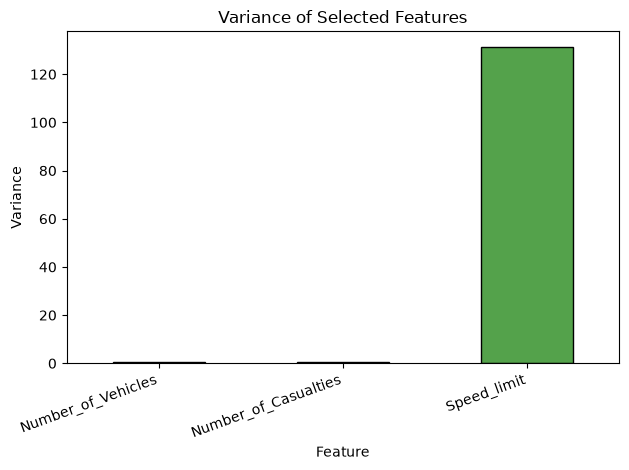

In [12]:
X_raw.var().plot(kind="bar", color=["#4C78A8", "#F58518", "#54A24B"][:len(feature_cols)], edgecolor="black")
plt.title("Variance of Selected Features"); plt.xlabel("Feature"); plt.ylabel("Variance")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

### Interpretation

Features with larger original units can have larger variance, motivating standardization before PCA.

## 9. Graph 2 — Feature selection F-scores

Plot ANOVA F-scores when the target and data support the calculation.

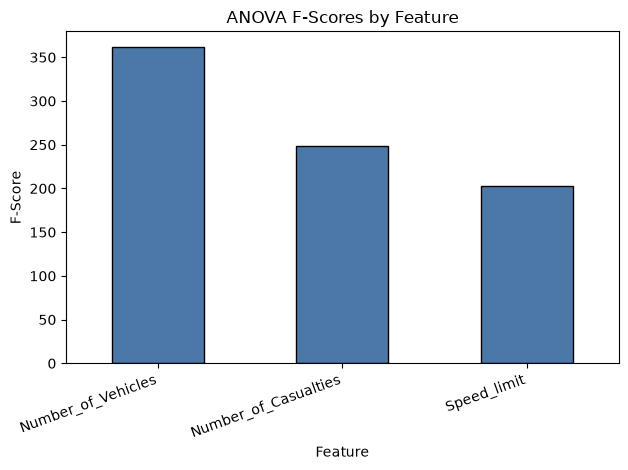

In [13]:
if not scores.empty:
    scores.plot(x="Feature", y="F_Score", kind="bar", legend=False, color="#4C78A8", edgecolor="black")
    plt.title("ANOVA F-Scores by Feature"); plt.xlabel("Feature"); plt.ylabel("F-Score")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
else:
    print("No feature-selection scores available to plot.")

### Interpretation

This plot ranks features by their statistical association with accident-severity categories.

## 10. Fit PCA and calculate explained variance

PCA creates new components from standardized features. Explained variance indicates how much variability each component captures.

In [14]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
ratios = pca_full.explained_variance_ratio_
variance_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(ratios))],
    "Explained Variance (%)": ratios * 100,
    "Cumulative Variance (%)": np.cumsum(ratios) * 100
})
display(variance_table.round(3))

,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,43.389,43.389
1,PC2,33.121,76.511
2,PC3,23.489,100.000


### Interpretation

The first component captures the largest possible share of variance; cumulative variance shows the share captured by the first several components.

## 11. Graph 3 — Explained variance by component

Compare the percentage of variance represented by each component.

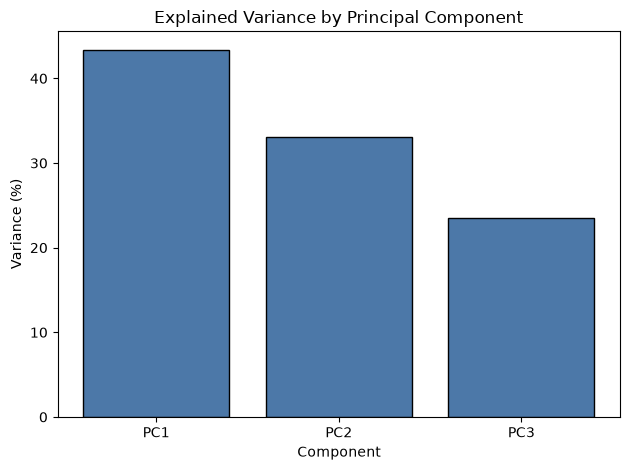

In [15]:
plt.bar([f"PC{i+1}" for i in range(len(ratios))], ratios*100, color="#4C78A8", edgecolor="black")
plt.title("Explained Variance by Principal Component"); plt.xlabel("Component"); plt.ylabel("Variance (%)")
plt.tight_layout(); plt.show()

### Interpretation

Taller bars indicate components that capture a larger share of the standardized features' variance.

## 12. Graph 4 — Cumulative explained variance

Use the curve to select a suitable number of components.

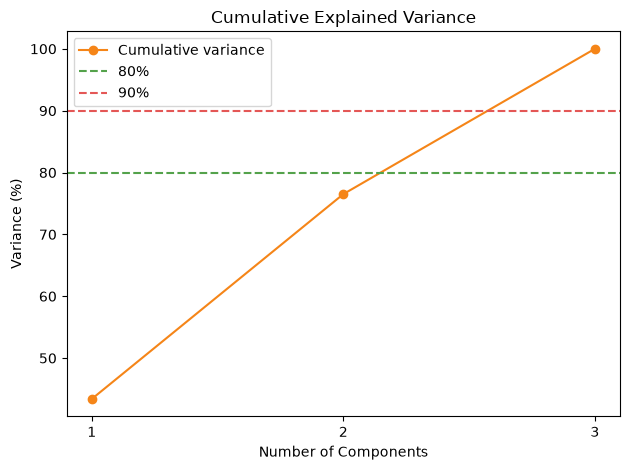

In [16]:
cum = np.cumsum(ratios)*100
plt.plot(range(1, len(cum)+1), cum, marker="o", color="#F58518", label="Cumulative variance")
plt.axhline(80, linestyle="--", color="#54A24B", label="80%")
plt.axhline(90, linestyle="--", color="#E45756", label="90%")
plt.title("Cumulative Explained Variance"); plt.xlabel("Number of Components"); plt.ylabel("Variance (%)")
plt.xticks(range(1, len(cum)+1)); plt.legend(); plt.tight_layout(); plt.show()

### Interpretation

The curve helps estimate how many components are needed for a chosen variance target; 80% and 90% are examples, not universal rules.

## 13. Reduce dimensionality

Select the minimum number of components needed to reach 90% cumulative explained variance, or use all available components if there are fewer.

In [17]:
TARGET_VARIANCE = 0.90
n_components = min(int(np.searchsorted(np.cumsum(ratios), TARGET_VARIANCE) + 1), len(feature_cols))
pca = PCA(n_components=n_components)
X_reduced = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_reduced, columns=[f"PC{i+1}" for i in range(n_components)], index=df.index)
print("Components selected:", n_components)
print("Variance retained:", f"{pca.explained_variance_ratio_.sum():.2%}")
display(pca_df.head())

Components selected: 3
Variance retained: 100.00%


,PC1,PC2,PC3
0,-1.848637,-5.295322,1.549387
1,-1.848637,-5.295322,1.549387
2,-0.111571,0.092238,-0.018154
3,-1.848637,-5.295322,1.549387
4,-1.848637,-5.295322,1.549387


### Interpretation

The reduced dataset represents the selected numeric features with fewer or equal component columns.

## 14. Graph 5 — PCA two-dimensional projection

Plot the first two components if available. A sample is used for readability with large datasets.

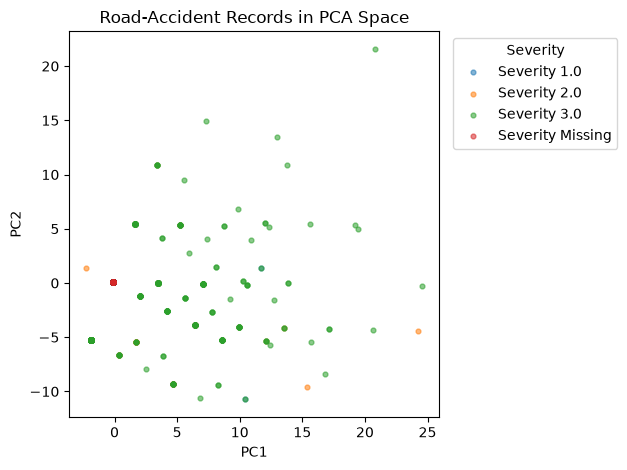

In [18]:
plot_df = pca_df.sample(min(len(pca_df), 12000), random_state=42)
if "PC2" in plot_df.columns:
    if "Accident_Severity" in df.columns:
        severity = df.loc[plot_df.index, "Accident_Severity"].astype("string").fillna("Missing")
        for category in sorted(severity.unique()):
            mask = severity == category
            plt.scatter(plot_df.loc[mask, "PC1"], plot_df.loc[mask, "PC2"], s=12, alpha=.55, label=f"Severity {category}")
        plt.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        plt.scatter(plot_df["PC1"], plot_df["PC2"], s=12, alpha=.55, color="#4C78A8")
    plt.title("Road-Accident Records in PCA Space"); plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.tight_layout(); plt.show()
else:
    print("Only one component selected; 2D plot unavailable.")

### Interpretation

The plot shows records in component space. Overlapping severity groups mean these selected features do not completely separate the groups in two dimensions.

## 15. Graph 6 — PCA feature loadings

Loadings show the contribution of each original feature to each component.

,PC1,PC2,PC3
Number_of_Vehicles,0.2957,0.9172,-0.2669
Number_of_Casualties,0.7032,-0.0199,0.7107
Speed_limit,0.6466,-0.3978,-0.6509


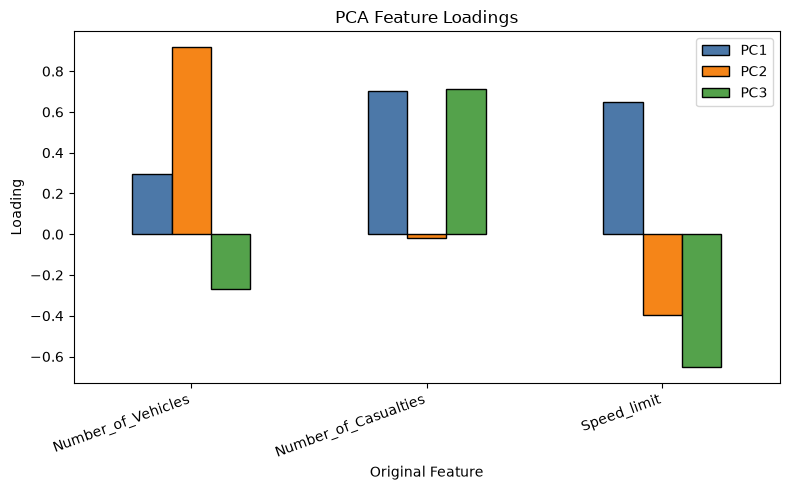

In [19]:
loadings = pd.DataFrame(pca.components_.T, index=feature_cols,
                        columns=[f"PC{i+1}" for i in range(n_components)])
display(loadings.round(4))
loadings.plot(kind="bar", figsize=(8,5), color=["#4C78A8", "#F58518", "#54A24B"][:n_components], edgecolor="black")
plt.title("PCA Feature Loadings"); plt.xlabel("Original Feature"); plt.ylabel("Loading")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

### Interpretation

Large absolute loadings indicate stronger contributions to a component. Signs indicate direction and can flip without changing the PCA solution's interpretation.

## 16. Save PCA output (optional)

Save the reduced component table separately; the original dataset is not overwritten.

In [20]:
PCA_OUTPUT = "road_accidents_week7_pca.csv"
# Uncomment to save:
# pca_df.to_csv(PCA_OUTPUT, index=False)
print("Original selected matrix:", X_raw.shape)
print("Reduced PCA matrix:", pca_df.shape)
print("Output filename if saved:", PCA_OUTPUT)

Original selected matrix: (1048575, 3)
Reduced PCA matrix: (1048575, 3)
Output filename if saved: road_accidents_week7_pca.csv


### Final conclusion

This notebook demonstrates feature selection, PCA, and variance visualization for the road-accident dataset. It standardizes selected numeric measurements, evaluates feature association with severity when possible, and visualizes explained variance, cumulative variance, PCA projection, and feature loadings. Graphs use color for clarity.